# 05 · Anomaly Score Estimator & Evaluation (paper §4.5, Eq. 13–15, Table 1/3/5, Fig. 3b)

<div dir="rtl" style="text-align:right">

مرحله‌ی inference بدون آموزش اضافه:

۱. embedding همه‌ی گره‌ها (گراف و متن) با مدل آموزش‌دیده (`model.embedding`).
۲. در هر **round** گره‌ها دوباره batch‌بندی و همسایه‌ها دوباره نمونه‌گیری می‌شوند؛ برای هر گره در هر view امتیاز «ناسازگاری» ساخته می‌شود (Eq. 13): منفی‌ها − مثبت + cross-entropy.
۳. $R$ round میانگین (**consistency**, Eq. 14) و انحراف معیار (**stability**, Eq. 15) می‌دهد: $S_i=\bar S_i+\text{std}_r(s_i^r)$.

امتیاز رسمی را با `model.inference` می‌گیرم؛ سپس همان محاسبه را با ماژول شفاف `views.py` تکرار می‌کنم تا امتیاز هر view و ablationها قابل رسم شوند (و با خروجی رسمی `assert` می‌شود).

</div>

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")      # Windows: avoid the duplicate-OpenMP abort that kills the kernel
import faulthandler; faulthandler.enable()          # prints a native traceback to the Jupyter log if the kernel dies
import sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn.functional as F
from torch.utils.data import DataLoader
from cmucl_nb import common as C, views as V

cfg = C.load_config(); args = C.as_args(cfg); device = C.get_device(cfg)
C.set_cpu_threads()                          # leave some CPU cores free so the laptop stays responsive
C.fetch_official_code()                      # official repo -> ./third_party/CMUCL (not copied into this repo)
from model import CMUCL, tokenize            # official model + tokenizer
from data import DataHelper                  # official neighbour sampler

ds = C.load_saved_dataset()
x = torch.from_numpy(ds["feats"]).to(device)
edge_index = torch.from_numpy(ds["edge_index"]).to(device)
labels, texts = ds["labels"], ds["texts"]
print(f"dataset={cfg['dataset']}  device={device}  torch threads={torch.get_num_threads()}  nodes={ds['n']} (of {cfg.get('n_full')})  anomalies={labels.sum()}")

dataset=Citeseer  device=cpu  torch threads=4  nodes=576 (of 3186)  anomalies=23


In [2]:
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
model = CMUCL(args).to(device); C.prepare_model(model)   # CPU: thread limit + gradient checkpointing (same maths, far less RAM)
trained = (C.ART / "trained_state.pt").exists()
model.load_state_dict(torch.load(C.ART / ("trained_state.pt" if trained else "init_state.pt"), map_location=device)); model.eval()
if not trained: print("WARNING: trained_state.pt not found -> scoring an UNTRAINED model (run notebook 04 first).")
Data = DataHelper(ds["edge_index"], args); n = ds["n"]
covered = np.zeros(n, bool); covered[Data.idx] = True
print(f"nodes covered by the official sampler: {covered.sum()}/{n}")

lenth of dataset 576
nodes covered by the official sampler: 576/576


<div dir="rtl" style="text-align:right">

## ۱) Embedding همه‌ی گره‌ها (همان کار main_train.py)

</div>

In [3]:
graph_features = torch.zeros((n, args.gnn_output), device=device)
text_features = torch.zeros((n, args.embed_dim), device=device)
t0 = time.time()
with torch.no_grad():
    for sb in DataLoader(Data, batch_size=args.batch_size, shuffle=True, num_workers=0):
        s_n, t_n = sb["s_n"], sb["t_n"]
        s_text = tokenize(texts[s_n.numpy()].tolist(), context_length=args.context_length).to(device)
        g_f, t_f = model.embedding(x, edge_index, s_n, t_n, s_text, None, device)     # t_n_text is unused inside the official method
        graph_features[s_n] = g_f; text_features[s_n] = t_f
print(f"embedding time {time.time()-t0:.1f}s")

embedding time 63.9s


<div dir="rtl" style="text-align:right">

## ۲) شاهد مستقیم برای ایده‌ی مقاله: سازگاری cross-modal گره‌های عادی بیشتر از ناهنجار است؟

</div>

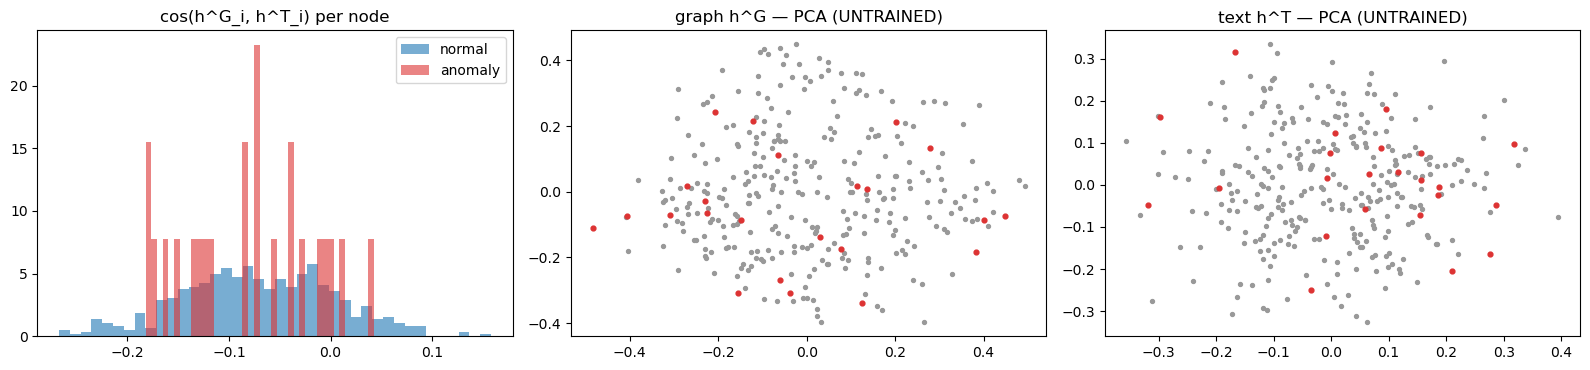

mean cos(G,T): normal -0.071 vs anomaly -0.081


In [4]:
from sklearn.decomposition import PCA
cos_gt = F.cosine_similarity(graph_features, text_features, dim=-1).cpu().numpy()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
m0, m1 = covered & (labels == 0), covered & (labels == 1)
ax[0].hist(cos_gt[m0], bins=40, alpha=.6, density=True, label="normal"); ax[0].hist(cos_gt[m1], bins=40, alpha=.6, density=True, label="anomaly", color="#d33")
ax[0].set_title("cos(h^G_i, h^T_i) per node"); ax[0].legend()
rng = np.random.RandomState(0); sel = np.r_[rng.choice(np.where(m1)[0], min(m1.sum(), 100), replace=False), rng.choice(np.where(m0)[0], min(m0.sum(), 300), replace=False)]
for a, Z, name in zip(ax[1:], [graph_features, text_features], ["graph h^G", "text h^T"]):
    P = PCA(2).fit_transform(F.normalize(Z[sel], dim=-1).cpu().numpy()); l = labels[sel]
    a.scatter(*P[l == 0].T, s=8, c="#999"); a.scatter(*P[l == 1].T, s=12, c="#d33"); a.set_title(f"{name} — PCA ({'trained' if trained else 'UNTRAINED'})")
plt.tight_layout(); C.savefig("05_embeddings_trained"); plt.show()
print(f"mean cos(G,T): normal {cos_gt[m0].mean():.3f} vs anomaly {cos_gt[m1].mean():.3f}")

<div dir="rtl" style="text-align:right">

## ۳) امتیاز رسمی: $R$ round با `model.inference`

</div>

In [5]:
R = args.rounds
multi = torch.zeros(n, R, device=device); t0 = time.time()
with torch.no_grad():
    for j in range(R):
        for ib, sb in enumerate(DataLoader(Data, batch_size=args.batch_size, shuffle=True, num_workers=0)):
            s_n, t_n = sb["s_n"], sb["t_n"]
            multi[s_n, j] = model.inference(x, graph_features, text_features, edge_index, s_n, t_n, None, None, device, j, ib)
        if (j + 1) % max(1, R // 8) == 0: print(f"round {j+1}/{R}  ({time.time()-t0:.0f}s)")
S_mean = multi.mean(1); S_std = multi.std(1) if R > 1 else torch.zeros_like(S_mean)       # torch.std = unbiased (official code)
S = (S_mean + S_std).cpu().numpy()
S_paper = (S_mean + (multi.std(1, unbiased=False) if R > 1 else 0)).cpu().numpy()          # Eq.15 literally (divide by R)

round 32/256  (3s)
round 64/256  (6s)
round 96/256  (9s)
round 128/256  (12s)
round 160/256  (15s)
round 192/256  (19s)
round 224/256  (22s)
round 256/256  (25s)


In [6]:
def evaluate(s, mask=None):
    m = np.ones(n, bool) if mask is None else mask
    return dict(AUC=100 * roc_auc_score(labels[m], s[m]), AP=100 * average_precision_score(labels[m], s[m]))
res = pd.DataFrame({
    "official estimator (all nodes)": evaluate(S),
    "official estimator (covered nodes only)": evaluate(S, covered),
    "Eq.15 literal std (/R), all nodes": evaluate(S_paper),
}).T.round(2); res

,AUC,AP
official estimator (all nodes),66.56,6.42
official estimator (covered nodes only),66.56,6.42
"Eq.15 literal std (/R), all nodes",66.55,6.42


<div dir="rtl" style="text-align:right">

- **all nodes** = همان چیزی که `main_train.py` رسمی محاسبه می‌کند (گره‌های منزوی با امتیاز صفر هم داخلند).
- **Eq.15 literal**: کد رسمی `torch.std` (مخرج $R-1$) دارد، مقاله مخرج $R$؛ اثر عملی معمولاً ناچیز است ولی گزارش می‌کنم.

</div>

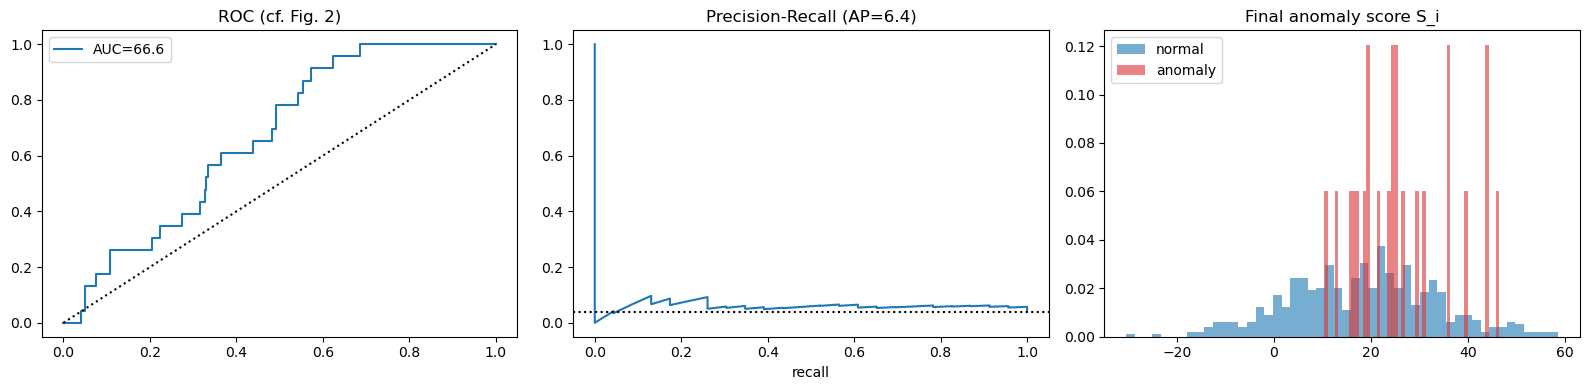

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
fpr, tpr, _ = roc_curve(labels, S); ax[0].plot(fpr, tpr, label=f"AUC={res.iloc[0]['AUC']:.1f}"); ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("ROC (cf. Fig. 2)"); ax[0].legend()
pr, rc, _ = precision_recall_curve(labels, S); ax[1].plot(rc, pr); ax[1].axhline(labels.mean(), color="k", ls=":"); ax[1].set_title(f"Precision-Recall (AP={res.iloc[0]['AP']:.1f})"); ax[1].set_xlabel("recall")
ax[2].hist(S[covered & (labels == 0)], bins=50, alpha=.6, density=True, label="normal"); ax[2].hist(S[covered & (labels == 1)], bins=50, alpha=.6, density=True, color="#d33", label="anomaly")
ax[2].set_title("Final anomaly score S_i"); ax[2].legend(); plt.tight_layout(); C.savefig("05_roc_pr_scores"); plt.show()

<div dir="rtl" style="text-align:right">

## ۴) AUC به تفکیک نوع ناهنجاری (مثل Table 4 مقاله) و بالاترین مشکوک‌ها

</div>

In [8]:
if ds["types"] is not None:
    names = {1: "contextual: insertion", 2: "contextual: replacement", 3: "structural: clique", 4: "structural: random edges"}
    print(pd.Series({names[t]: round(100 * roc_auc_score(labels[(ds["types"] == 0) | (ds["types"] == t)], S[(ds["types"] == 0) | (ds["types"] == t)]), 2) for t in names}, name="AUC"))
else:
    print("Real dataset: anomaly types are not stored in the .mat file, so no per-type breakdown.")
K = int(labels.sum()); top = np.argsort(-S)[:K]
print(f"precision@{K} = {labels[top].mean():.3f}")
pd.DataFrame({"node": top[:15], "score": S[top[:15]].round(3), "label": labels[top[:15]], "text": [str(texts[i])[:90] for i in top[:15]]})

Real dataset: anomaly types are not stored in the .mat file, so no per-type breakdown.
precision@23 = 0.000


,node,score,label,text
0,507,58.606998,0,Examining Locally Varying Weights for Nearest ...
1,85,58.173000,0,Exploiting Synergy Between Ontologies and Reco...
2,247,55.158001,0,Data Mining for Intelligent Web Caching The pa...
3,370,55.051998,0,A Microeconomic View of Data Mining We present...
4,261,54.333000,0,Static and Dynamic Information Organization wi...
5,446,54.039001,0,Theseus: Categorization by Context Introductio...
6,551,52.601002,0,A Feature-Relevance Heuristic for Indexing and...
7,498,52.051998,0,Autoepistemic Logic of Knowledge and Beliefs I...
8,238,51.028999,0,Discovering Structural Association of Semistru...
9,345,50.369999,0,WebMate: A Personal Agent for Browsing and Sea...


<div dir="rtl" style="text-align:right">

## ۵) امتیاز هر view و تایید عددی با کد رسمی
با `views.py` همان محاسبه را برای $R_a=\min(R,32)$ round تکرار می‌کنم؛ در اولین batch با خروجی `model.inference` رسمی `assert` می‌شود. از همین حلقه، امتیاز هر view و نسخه‌ی **بدون cross-entropy** (Table 5 مقاله) هم به دست می‌آید.

</div>

In [9]:
Ra = min(R, 32); scale = model.logit_scale.exp()
pv = {k: torch.zeros(n, Ra, device=device) for k in V.VIEW_INFO}; full = torch.zeros(n, Ra, device=device); noce = torch.zeros(n, Ra, device=device)
checked = False
with torch.no_grad():
    for j in range(Ra):
        for ib, sb in enumerate(DataLoader(Data, batch_size=args.batch_size, shuffle=True, num_workers=0)):
            s_n, t_n = sb["s_n"], sb["t_n"]
            lg = V.similarity_logits(V.stored_features(graph_features, text_features, s_n, t_n, args.neigh_num), scale)
            s_full, parts = V.anomaly_score(lg, args.gamma, True, return_views=True)
            full[s_n, j] = s_full; noce[s_n, j] = V.anomaly_score(lg, args.gamma, False)
            for k in pv: pv[k][s_n, j] = parts[k]["score"]
            if not checked:
                off = model.inference(x, graph_features, text_features, edge_index, s_n, t_n, None, None, device, j, ib)
                assert torch.allclose(off, s_full, atol=1e-3, rtol=1e-4), "mirror differs from official inference!"; checked = True
                print("OK: views.py reproduces model.inference on a real batch")

OK: views.py reproduces model.inference on a real batch


In [10]:
est = lambda M: (M.mean(1) + (M.std(1) if M.shape[1] > 1 else 0)).cpu().numpy()
rows = {f"view {k} ({V.VIEW_INFO[k]['eq']}) alone": evaluate(est(pv[k])) for k in pv}
rows["all views, with CE (full)"] = evaluate(est(full)); rows["all views, WITHOUT cross-entropy term"] = evaluate(est(noce))
pd.DataFrame(rows).T.round(2)

,AUC,AP
view nn (Eq.4) alone,53.42,4.68
view cc (Eq.5) alone,81.85,12.79
view nc (Eq.8) alone,62.64,5.75
view cn (Eq.9) alone,80.45,11.19
view gg (Eq.11 (graph)) alone,95.61,62.09
view tt (Eq.11 (text)) alone,95.44,52.24
"all views, with CE (full)",66.81,6.42
"all views, WITHOUT cross-entropy term",66.91,6.45


<div dir="rtl" style="text-align:right">

## ۶) Ablation روی estimator (Table 3 پایین) و حساسیت به $R$ (Fig. 3b)

</div>

,AUC,AP
"w/ cons (mean only, Eq.14)",60.96,5.23
w/ stab (std only),92.89,23.65
Full (mean + std),66.56,6.42


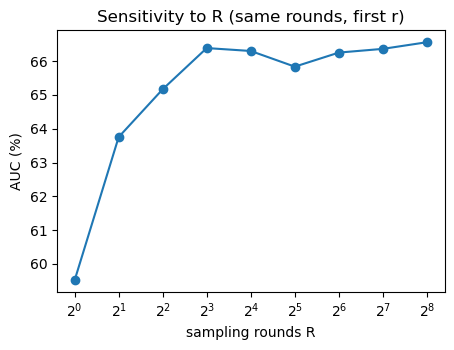

In [11]:
variants = {"w/ cons (mean only, Eq.14)": S_mean.cpu().numpy(), "w/ stab (std only)": S_std.cpu().numpy(), "Full (mean + std)": S}
abl = pd.DataFrame({k: evaluate(v) for k, v in variants.items()}).T.round(2); display(abl)
Rs = [r for r in [1, 2, 4, 8, 16, 32, 64, 128, 256, 512] if r <= R]
curve = [100 * roc_auc_score(labels, (multi[:, :r].mean(1) + (multi[:, :r].std(1) if r > 1 else 0)).cpu().numpy()) for r in Rs]
plt.figure(figsize=(5, 3.4)); plt.semilogx(Rs, curve, "o-", base=2); plt.xlabel("sampling rounds R"); plt.ylabel("AUC (%)"); plt.title("Sensitivity to R (same rounds, first r)")
C.savefig("05_rounds_sensitivity"); plt.show()

<div dir="rtl" style="text-align:right">

## ۷) ذخیره‌ی خروجی‌ها و مقایسه‌ی صادقانه با مقاله

</div>

In [12]:
pd.DataFrame({"node": np.arange(n), "score": S, "label": labels, "covered": covered}).to_csv(C.ART / "scores.csv", index=False)
metrics = dict(dataset=cfg["dataset"], n_nodes=n, n_nodes_full=cfg.get("n_full"), trained=trained, rounds=R, seed=cfg["seed"],
               auc_all=res.iloc[0]["AUC"], ap_all=res.iloc[0]["AP"], auc_covered=res.iloc[1]["AUC"], ap_covered=res.iloc[1]["AP"],
               auc_cons_only=abl.iloc[0]["AUC"], auc_stab_only=abl.iloc[1]["AUC"])
json.dump(metrics, open(C.ART / "metrics.json", "w"), indent=1)
print(json.dumps(metrics, indent=1))
if cfg["dataset"] == "Citeseer":
    print("\nPaper (Table 1/3/5, Citeseer, mean of 5 seeds, RTX 4090): AUC 82.29±1.25 | AP 34.62±0.24 | w/ cons 80.39 | w/ stab 67.60 | w/o entropy 80.57 | 273 s")
    if n < cfg.get("n_full", n): print(f"NOTE: only {n} of {cfg['n_full']} nodes were used (CPU budget) -> NOT comparable with the paper's full-graph numbers.")
    else: print("NOTE: single seed; the paper averages 5 seeds, so expect run-to-run differences.")
else:
    print("\nDataset is not Citeseer -> no paper numbers to compare against.")

{
 "dataset": "Citeseer",
 "n_nodes": 576,
 "n_nodes_full": 3186,
 "trained": false,
 "rounds": 256,
 "seed": 1,
 "auc_all": 66.56,
 "ap_all": 6.42,
 "auc_covered": 66.56,
 "ap_covered": 6.42,
 "auc_cons_only": 60.96,
 "auc_stab_only": 92.89
}

Paper (Table 1/3/5, Citeseer, mean of 5 seeds, RTX 4090): AUC 82.29±1.25 | AP 34.62±0.24 | w/ cons 80.39 | w/ stab 67.60 | w/o entropy 80.57 | 273 s
NOTE: only 576 of 3186 nodes were used (CPU budget) -> NOT comparable with the paper's full-graph numbers.
